# Phase 1 walkthrough: data audit and cleaning

This notebook runs Phase 1 and then walks through it. Section 0 notes the numbers in the committed `results/phase1/` files and re-runs the Phase 1 scripts, and section 8 checks that the re-run reproduces them. The test set is never opened.

**How to use it:** run the cells from top to bottom (Shift+Enter). Read the note above each cell first, then say in your own words what the output shows. The cell marked **Try it** is for you to edit.

In [1]:
import os
import re
import subprocess
import sys
import time
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
from IPython.display import Image, display

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)


def run_step(script, *args, show=25):
    """Run one project script from src/ with this notebook's Python, from the repository root."""
    t0 = time.perf_counter()
    env = {**os.environ, "PYTHONIOENCODING": "utf-8"}
    r = subprocess.run([sys.executable, "-X", "faulthandler=0", str(ROOT / "src" / script), *args], cwd=ROOT,
                       capture_output=True, text=True, encoding="utf-8", errors="replace", env=env)
    lines = (r.stdout or "").rstrip().splitlines()
    if show:
        if len(lines) > show:
            print(f"... ({len(lines) - show} earlier lines not shown)")
        print("\n".join(lines[-show:]))
    print(f"[{' '.join([script, *args])} finished in {time.perf_counter() - t0:.1f} s, exit code {r.returncode}]")
    if r.returncode != 0:
        print(r.stderr[-3000:])
        raise RuntimeError(f"{script} failed")


print("Research prototype, not a diagnostic tool. The test set is not used in this notebook.")

from data import (CLASS_ORDER, FILL_COLS, RAW, RAW_SHA256, TARGET, load_dev, load_raw, sha256_of)
from validator import consistency_flags, screen_frame, validate_record

Research prototype, not a diagnostic tool. The test set is not used in this notebook.


## 0. Run Phase 1

First we note the committed reports (a snapshot). Then the three Phase 1 scripts run exactly as they would on the command line: the dataset check, the cleaning and the data report. They rewrite `results/phase1/`.

In [2]:
P1 = ROOT / "results" / "phase1"
before_clean = (P1 / "cleaning_report.txt").read_text(encoding="utf-8")
before_data = (P1 / "data_report.txt").read_text(encoding="utf-8")

run_step("check_dataset.py")
run_step("phase1_clean.py")
run_step("phase1_data_report.py")

file: diagnosed_cbc_data_v4.csv, bytes: 125590 (expected 125590)
sha256: f7dee8d4fe500aec6e8e4bfbeb6df6b83bc86bef03d540721e0aeaad2759fcdb
expected: f7dee8d4fe500aec6e8e4bfbeb6df6b83bc86bef03d540721e0aeaad2759fcdb
OK: dataset matches
[check_dataset.py finished in 0.4 s, exit code 0]


... (71 earlier lines not shown)
PDW flag = 1 in 303 rows; of those, fill count 6: 303
NEUTn > WBC rows with fill count 6: 35 of 41
fill count 6 by class, kept rows only (filled / kept rows of that class, share):
  Healthy: 216 / 256 (84.4%)
  Normocytic hypochromic anemia: 82 / 209 (39.2%)
  Normocytic normochromic anemia: 187 / 202 (92.6%)
  Iron deficiency anemia: 26 / 144 (18.1%)
  Thrombocytopenia: 14 / 54 (25.9%)
  Other microcytic anemia: 33 / 41 (80.5%)
  Leukemia: 20 / 35 (57.1%)
  Macrocytic anemia: 10 / 13 (76.9%)
  Leukemia with thrombocytopenia: 1 / 9 (11.1%)
  all kept rows: 589 / 963 (61.2%)

== 6. development rows after cleaning, per class ==
  Healthy: 256 (26.6%)
  Normocytic hypochromic anemia: 209 (21.7%)
  Normocytic normochromic anemia: 202 (21.0%)
  Iron deficiency anemia: 144 (15.0%)
  Thrombocytopenia: 54 (5.6%)
  Other microcytic anemia: 41 (4.3%)
  Leukemia: 35 (3.6%)
  Macrocytic anemia: 13 (1.3%)
  Leukemia with thrombocytopenia: 9 (0.9%)
  total: 963; larg

... (76 earlier lines not shown)
    Healthy: 256 / 256
    Normocytic hypochromic anemia: 197 / 209
    Normocytic normochromic anemia: 201 / 202
    Iron deficiency anemia: 143 / 144
    Thrombocytopenia: 54 / 54
    Other microcytic anemia: 39 / 41
    Leukemia: 35 / 35
    Macrocytic anemia: 13 / 13
    Leukemia with thrombocytopenia: 9 / 9
  microcytic split, MCHC by label (min / median / max):
    Iron deficiency anemia: 20.3 / 29.55 / 31.8 (n=144)
    Other microcytic anemia: 31.4 / 32 / 38.7 (n=41)
  disagreeing rows (16), true label -> cascade output:
    Iron deficiency anemia -> Healthy: 1
    Normocytic hypochromic anemia -> Normocytic normochromic anemia: 12
    Normocytic normochromic anemia -> Leukemia with thrombocytopenia: 1
    Other microcytic anemia -> Leukemia with thrombocytopenia: 1
    Other microcytic anemia -> Thrombocytopenia: 1

== F. feature pairs with Spearman |rho| >= 0.9 (other rows) ==
  LYMp - NEUTp: -0.939
  HGB - HCT: 0.957
  MCV - MCH: 0.915
  PLT -

## 1. Is the raw file unchanged?

A hash is a fingerprint of a file. If one byte changes, the fingerprint changes completely. We compare today's fingerprint with the one recorded on 7 Nov.

In [3]:
raw = load_raw()
print("rows:", len(raw), " columns:", raw.shape[1], " empty cells:", int(raw.isna().sum().sum()))
print("hash matches the 7 Nov record:", sha256_of(RAW) == RAW_SHA256)

rows: 1281  columns: 15  empty cells: 0
hash matches the 7 Nov record: True


## 2. The split

Exact duplicates were removed first (49 rows), then one stratified 80/20 split was made with seed 42. Stratified means each part keeps the same class mix. `src/phase1_clean.py` re-runs this and confirms it gives the same split. Only the development side is shown here. The test rows stay locked until the final evaluation.

In [4]:
split = pd.read_csv(ROOT / "results" / "split" / "dev_test_split.csv", usecols=["raw_row", "set"])
print("rows per set:", split["set"].value_counts().to_dict())
load_dev(clean=False)[TARGET].value_counts().reindex(CLASS_ORDER).rename("development rows").to_frame()

rows per set: {'dev': 985, 'test': 247}


,development rows
Diagnosis,
Healthy,258
Normocytic hypochromic anemia,217
Normocytic normochromic anemia,204
Iron deficiency anemia,147
Thrombocytopenia,57
Other microcytic anemia,45
Leukemia,35
Macrocytic anemia,13
Leukemia with thrombocytopenia,9


## 3. The input validator

The validator is the gatekeeper. It checks each of the 14 columns against loose screening ranges (your own limits, not clinical ranges) and lists every reason a record fails. The agent uses the same code at prediction time.

In [5]:
GOOD = {"WBC": 7.4, "LYMp": 25.8, "NEUTp": 77.5, "LYMn": 1.9, "NEUTn": 5.1, "RBC": 4.6,
        "HGB": 12.2, "HCT": 46.2, "MCV": 86.6, "MCH": 27.7, "MCHC": 32.0, "PLT": 213.0,
        "PDW": 14.3, "PCT": 0.26}
print("good record ->", validate_record(GOOD) or "valid")
for col, value in [("HGB", -10), ("MCV", -79.3), ("HCT", 3715), ("NEUTp", 5317), ("MCH", 3117)]:
    print(f"{col} = {value}:", validate_record({**GOOD, col: value}))
print("NEUTn larger than WBC is only flagged:", consistency_flags({**GOOD, "NEUTn": 9.0, "WBC": 7.0}))

good record -> valid
HGB = -10: ['HGB=-10 outside [0, 25]']
MCV = -79.3: ['MCV=-79.3 outside [40, 150]']
HCT = 3715: ['HCT=3715 outside [5, 75]']
NEUTp = 5317: ['NEUTp=5317 outside [0, 100]']
MCH = 3117: ['MCH=3117 outside [10, 50]']
NEUTn larger than WBC is only flagged: ['NEUTn > WBC']


**Try it:** change the values below and run the cell. What does the validator say about a missing column or a text value?

In [6]:
my_record = {**GOOD, "PLT": 0, "MCHC": 50}
print(validate_record(my_record) or "valid")

['MCHC=50 outside [20, 45]', 'PLT=0 outside (0, 2000]']


## 4. Cleaning the development rows

We run the validator on all 985 development rows and drop the rows it rejects (a rule fixed before cleaning). Most rejected values look like a lost decimal point, but fixing them would mean guessing, so we drop them.

In [7]:
dev_all = load_dev(clean=False)
reasons = screen_frame(dev_all)
valid = reasons == ""
n_rejected, n_kept = int((~valid).sum()), int(valid.sum())
print(f"rejected {n_rejected} of {len(dev_all)}, kept {n_kept}")
table = pd.DataFrame({"development rows": dev_all[TARGET].value_counts(),
                      "rejected": dev_all.loc[~valid, TARGET].value_counts()}).reindex(CLASS_ORDER).fillna(0).astype(int)
table

rejected 22 of 985, kept 963


,development rows,rejected
Diagnosis,,
Healthy,258,2
Normocytic hypochromic anemia,217,8
Normocytic normochromic anemia,204,2
Iron deficiency anemia,147,3
Thrombocytopenia,57,3
Other microcytic anemia,45,4
Leukemia,35,0
Macrocytic anemia,13,0
Leukemia with thrombocytopenia,9,0


## 5. The mean-fill pattern

In many rows six columns hold exactly the same value (the column average). That looks like missing values were filled before upload. The share differs a lot by class, so a model could learn the filling instead of the biology.

mean-filled rows: 589 of 963


,mean-filled share (%)
Diagnosis,
Healthy,84.4
Normocytic hypochromic anemia,39.2
Normocytic normochromic anemia,92.6
Iron deficiency anemia,18.1
Thrombocytopenia,25.9
Other microcytic anemia,80.5
Leukemia,57.1
Macrocytic anemia,76.9
Leukemia with thrombocytopenia,11.1


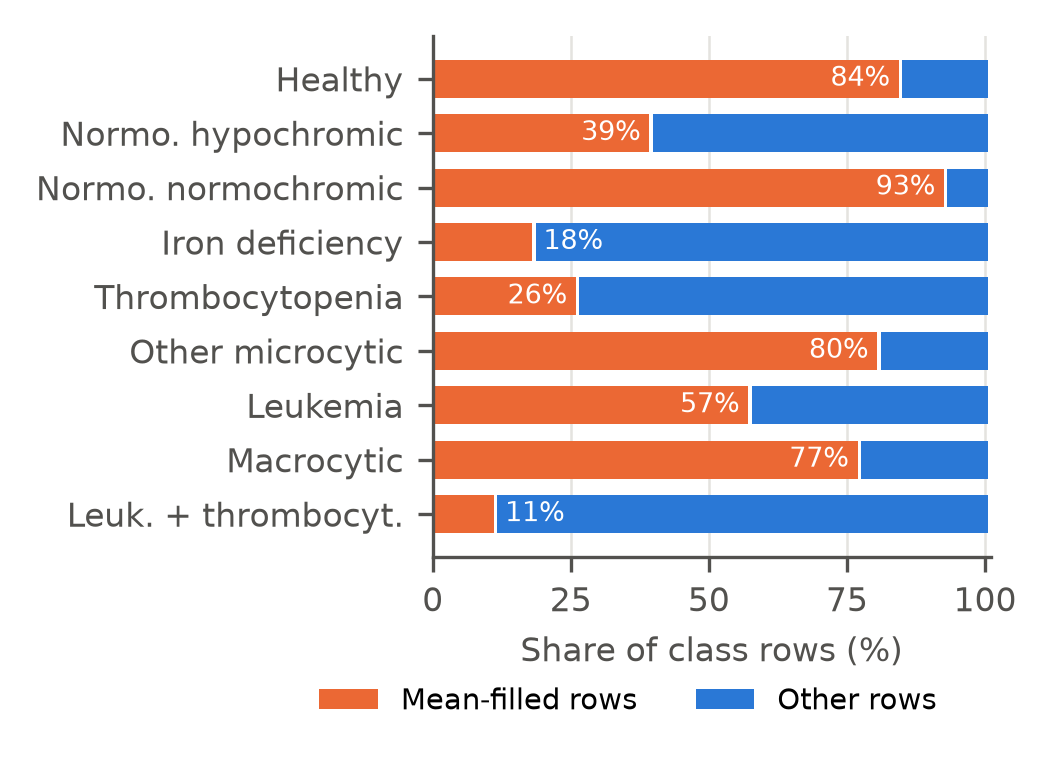

In [8]:
dev = load_dev(clean=True)
filled = dev["fill_count"] == 6
n_filled = int(filled.sum())
share = (dev.groupby(TARGET)["fill_count"].apply(lambda s: (s == 6).mean() * 100)).reindex(CLASS_ORDER).round(1)
print(f"mean-filled rows: {n_filled} of {len(dev)}")
display(share.rename("mean-filled share (%)").to_frame())
display(Image(filename=str(ROOT / "results" / "phase1" / "figures" / "fig_fill_by_class.png"), width=520))

## 6. Do the columns mean what their names say?

Two checks on the rows that are not mean-filled. First, the absolute lymphocyte count should equal WBC times the lymphocyte percentage. Second, the textbook formula MCV = HCT × 10 / RBC should hold if HCT is in % and RBC in 10¹²/L (the formula is still unverified until cited).

In [9]:
def within(obs, calc, tol):
    return ((obs - calc).abs() / obs.abs() <= tol).mean() * 100

o = dev[~filled]
print(f"LYMn = WBC x LYMp / 100 within 5%: {within(o['LYMn'], o['WBC'] * o['LYMp'] / 100, 0.05):.1f}% of other rows")
mcv_calc = dev["HCT"] * 10 / dev["RBC"]
print(f"MCV = HCT x 10 / RBC within 2%: other rows {within(dev.loc[~filled, 'MCV'], mcv_calc[~filled], 0.02):.1f}%, "
      f"filled rows {within(dev.loc[filled, 'MCV'], mcv_calc[filled], 0.02):.1f}%")

LYMn = WBC x LYMp / 100 within 5%: 91.4% of other rows
MCV = HCT x 10 / RBC within 2%: other rows 98.7%, filled rows 4.8%


The formula holds in real rows and fails in filled rows, because the filled HCT is a constant. That supports both the unit reading and the mean-fill reading.

## 7. The label rule (the big finding)

A simple cascade with six round cut-offs, read off the development data, reproduces almost every label. The cut-offs are not clinical and never go into the rule engine. We reuse the cascade function from `src/phase2_rules_baseline.py` and merge the two microcytic labels, as in the Phase 1 report.

In [10]:
from phase2_rules_baseline import cascade_predict

p = {"hgb": 13.0, "plt": 150.0, "wbc": 10.0, "mcv_micro": 80.0, "mcv_macro": 100.0,
     "mchc_normo": 32.0, "mchc_ida_oma": 0.0}
merge = {"Iron deficiency anemia": "Microcytic", "Other microcytic anemia": "Microcytic"}
pred = dev.apply(lambda r: cascade_predict(r, p), axis=1).replace(merge)
truth = dev[TARGET].replace(merge)
n_agree = int((pred == truth).sum())
print(f"cascade agrees with the label in {n_agree} of {len(dev)} rows ({100 * n_agree / len(dev):.1f}%)")
pd.crosstab(truth[pred != truth], pred[pred != truth])

cascade agrees with the label in 947 of 963 rows (98.3%)


col_0,Healthy,Leukemia with thrombocytopenia,Normocytic normochromic anemia,Thrombocytopenia
Diagnosis,,,,
Microcytic,1,1,0,1
Normocytic hypochromic anemia,0,0,12,0
Normocytic normochromic anemia,0,1,0,0


## 8. Did the re-run reproduce the committed results?

The re-run reports must be identical to the committed ones (the snapshot from section 0), and the numbers recomputed in this notebook must match them. If anything differs, this cell fails.

In [11]:
assert (P1 / "cleaning_report.txt").read_text(encoding="utf-8") == before_clean, "cleaning report changed"
assert (P1 / "data_report.txt").read_text(encoding="utf-8") == before_data, "data report changed"
clean_txt, data_txt = before_clean, before_data
saved_rejected, saved_kept = map(int, re.search(r"rows rejected: (\d+) of \d+; rows kept: (\d+)", clean_txt).groups())
saved_filled = int(re.search(r"all kept rows: (\d+) / \d+", clean_txt).group(1))
saved_agree = int(re.search(r"label \(IDA and other microcytic merged\): (\d+) /", data_txt).group(1))
assert (n_rejected, n_kept, n_filled, n_agree) == (saved_rejected, saved_kept, saved_filled, saved_agree)
print("re-run identical to the committed reports, recomputed numbers match:", (n_rejected, n_kept, n_filled, n_agree))

re-run identical to the committed reports, recomputed numbers match: (22, 963, 589, 947)


## 9. Questions for you (answer without looking)

1. How many development rows did the validator reject, and why did we drop them instead of fixing them?
2. Give one piece of evidence that the six columns with a repeated value were mean-filled, using the CBC formulas.
3. Why must the cut-offs from the label-rule check (HGB 13, PLT 150, WBC 10 and so on) not go into the rule engine?